In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

while not os.path.isdir('data') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
print("cwd:", os.getcwd())

master = pd.read_csv('data/processed/aqi_weather_master.csv', parse_dates=['date'])
hist = master[master['data_source'] == 'kaggle_historical'][['city', 'date', 'AQI']].copy()

# full daily calendar per city, so a missing day appears as NaN instead of a skipped row
frames = []
for city, g in hist.groupby('city'):
    idx = pd.date_range(g['date'].min(), g['date'].max(), freq='D')
    s = g.set_index('date')['AQI'].reindex(idx)
    frames.append(pd.DataFrame({'city': city, 'date': idx, 'AQI': s.values}))
daily = pd.concat(frames, ignore_index=True)

def longest_gap(x):
    isna = x.isna().astype(int)
    runs = isna.groupby((isna == 0).cumsum()).sum()
    return int(runs.max())

summary = daily.groupby('city').agg(
    first_date=('date', 'min'), last_date=('date', 'max'),
    days=('AQI', 'size'), with_aqi=('AQI', lambda x: x.notna().sum()))
summary['longest_gap_days'] = daily.groupby('city')['AQI'].apply(longest_gap)
print(summary)

train_n = daily[(daily['date'] < '2020-01-01') & daily['AQI'].notna()].groupby('city').size()
test_n = daily[(daily['date'] >= '2020-01-01') & daily['AQI'].notna()].groupby('city').size()
print()
print(pd.DataFrame({'train_days_with_aqi': train_n, 'test_days_with_aqi': test_n}))

cwd: C:\Users\91935\PycharmProjects\AQi project
          first_date  last_date  days  with_aqi  longest_gap_days
city                                                             
Bengaluru 2015-01-01 2020-07-01  2009      1910                79
Chennai   2015-01-01 2020-07-01  2009      1884                82
Delhi     2015-01-01 2020-07-01  2009      1999                 4
Kolkata   2018-04-10 2020-07-01   814       754                59
Lucknow   2015-01-01 2020-07-01  2009      1893                79
Mumbai    2015-01-01 2020-07-01  2009       775              1222
Patna     2015-06-01 2020-07-01  1858      1459               171

           train_days_with_aqi  test_days_with_aqi
city                                              
Bengaluru                 1727                 183
Chennai                   1701                 183
Delhi                     1816                 183
Kolkata                    571                 183
Lucknow                   1710                 183


In [2]:
daily = daily.sort_values(['city', 'date']).reset_index(drop=True)
g = daily.groupby('city')['AQI']

lag_cols = [f'lag_{k}' for k in range(1, 8)]
for k in range(1, 8):
    daily[f'lag_{k}'] = g.shift(k)
daily['roll7_mean'] = g.transform(lambda x: x.shift(1).rolling(7, min_periods=7).mean())
daily['month'] = daily['date'].dt.month
daily['is_weekend'] = (daily['date'].dt.dayofweek >= 5).astype(int)

feature_cols = lag_cols + ['roll7_mean', 'month', 'is_weekend']

# leakage check: Delhi's lag_1 on 2019-06-15 must equal its AQI on 2019-06-14
d = daily[daily['city'] == 'Delhi'].set_index('date')
print("lag_1 on 2019-06-15:", d.loc['2019-06-15', 'lag_1'], "| AQI on 2019-06-14:", d.loc['2019-06-14', 'AQI'])

model_df = daily.dropna(subset=['AQI'] + feature_cols).copy()
train = model_df[model_df['date'] < '2020-01-01']
test = model_df[model_df['date'] >= '2020-01-01']

print("\nRows kept (train / test):", len(train), "/", len(test))
print("Rows with AQI before the complete-history filter:", int(daily['AQI'].notna().sum()))
print()
print(pd.DataFrame({
    'train': train.groupby('city').size(),
    'test': test.groupby('city').size()
}))
print("\nTrain:", train['date'].min().date(), "to", train['date'].max().date())
print("Test: ", test['date'].min().date(), "to", test['date'].max().date())

lag_1 on 2019-06-15: 167.0 | AQI on 2019-06-14: 167.0

Rows kept (train / test): 8831 / 1281
Rows with AQI before the complete-history filter: 10674

           train  test
city                  
Bengaluru   1670   183
Chennai     1630   183
Delhi       1779   183
Kolkata      557   183
Lucknow     1632   183
Mumbai       552   183
Patna       1011   183

Train: 2015-01-08 to 2019-12-31
Test:  2020-01-01 to 2020-07-01


In [5]:
def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

test = test.copy()
test['pred_persist'] = test['lag_1']
test['pred_roll7'] = test['roll7_mean']

print("Delhi examples (predicting day t from data up to t-1):")
print(test[test['city'] == 'Delhi'][['date', 'lag_1', 'AQI', 'pred_persist']].head(5).to_string(index=False))

rows = []
for name, col in [('Persistence (yesterday)', 'pred_persist'), ('7-day mean', 'pred_roll7')]:
    for city, g in list(test.groupby('city')) + [('ALL', test)]:
        rows.append({'baseline': name, 'city': city, 'n': len(g),
                     'mean_AQI': round(g['AQI'].mean(), 1),
                     'RMSE': round(rmse(g['AQI'], g[col]), 1),
                     'MAE': round(mae(g['AQI'], g[col]), 1)})
baseline_table = pd.DataFrame(rows)
print()
print(baseline_table.to_string(index=False))

print("\nMean AQI by month in the test period (all cities):")
print(test.groupby(test['date'].dt.month)['AQI'].mean().round(1))

Delhi examples (predicting day t from data up to t-1):
      date  lag_1   AQI  pred_persist
2020-01-01  417.0 492.0         417.0
2020-01-02  492.0 485.0         492.0
2020-01-03  485.0 426.0         485.0
2020-01-04  426.0 366.0         426.0
2020-01-05  366.0 354.0         366.0

               baseline      city    n  mean_AQI  RMSE  MAE
Persistence (yesterday) Bengaluru  183      79.7  10.5  7.8
Persistence (yesterday)   Chennai  183      80.3  17.7 10.9
Persistence (yesterday)     Delhi  183     181.7  39.9 29.6
Persistence (yesterday)   Kolkata  183     117.3  31.4 20.5
Persistence (yesterday)   Lucknow  183     157.1  45.1 33.8
Persistence (yesterday)    Mumbai  183     103.6  23.8 14.6
Persistence (yesterday)     Patna  183     162.3  34.5 23.1
Persistence (yesterday)       ALL 1281     126.0  31.1 20.0
             7-day mean Bengaluru  183      79.7  12.5  9.8
             7-day mean   Chennai  183      80.3  21.6 13.7
             7-day mean     Delhi  183     181.7  50.2 3

In [6]:
!{sys.executable} -m pip install scikit-learn

'{sys.executable}' is not recognized as an internal or external command,
operable program or batch file.


In [7]:
from sklearn.ensemble import RandomForestRegressor

def design(df):
    X = df[feature_cols].copy()
    return X.join(pd.get_dummies(df['city'], prefix='city').astype(int))

X_train = design(train)
X_test = design(test).reindex(columns=X_train.columns, fill_value=0)

rf_params = dict(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)

rf_direct = RandomForestRegressor(**rf_params).fit(X_train, train['AQI'])
test['pred_rf'] = rf_direct.predict(X_test)

rf_delta = RandomForestRegressor(**rf_params).fit(X_train, train['AQI'] - train['lag_1'])
test['pred_rf_delta'] = test['lag_1'] + rf_delta.predict(X_test)

methods = {'Persistence (yesterday)': 'pred_persist',
           '7-day mean': 'pred_roll7',
           'RF, predicts level': 'pred_rf',
           'RF, predicts change': 'pred_rf_delta'}

base_mae = mae(test['AQI'], test['pred_persist'])
rows = []
for name, col in methods.items():
    m = mae(test['AQI'], test[col])
    rows.append({'method': name,
                 'RMSE': round(rmse(test['AQI'], test[col]), 1),
                 'MAE': round(m, 1),
                 'MAE vs persistence': f"{(m / base_mae - 1) * 100:+.1f}%"})
print(pd.DataFrame(rows).to_string(index=False))

print("\nRMSE by city:")
print(pd.DataFrame({name: {c: round(rmse(g['AQI'], g[col]), 1) for c, g in test.groupby('city')}
                    for name, col in methods.items()}))

print("\nTop features (level model):")
print(pd.Series(rf_direct.feature_importances_, index=X_train.columns)
        .sort_values(ascending=False).head(6).round(3))

                 method  RMSE  MAE MAE vs persistence
Persistence (yesterday)  31.1 20.0              +0.0%
             7-day mean  37.4 24.8             +23.7%
     RF, predicts level  29.6 19.7              -1.5%
    RF, predicts change  29.2 19.5              -2.6%

RMSE by city:
           Persistence (yesterday)  7-day mean  RF, predicts level  \
Bengaluru                     10.5        12.5                10.8   
Chennai                       17.7        21.6                17.4   
Delhi                         39.9        50.2                37.9   
Kolkata                       31.4        37.3                29.5   
Lucknow                       45.1        52.2                43.2   
Mumbai                        23.8        30.6                23.7   
Patna                         34.5        40.0                31.0   

           RF, predicts change  
Bengaluru                 10.5  
Chennai                   17.1  
Delhi                     36.9  
Kolkata               

                 method  RMSE_all  MAE_all  RMSE_Delhi  MAE_Delhi
Persistence (yesterday)      31.1     20.0        39.9       29.6
             7-day mean      37.4     24.8        50.2       36.9
     RF, predicts level      29.6     19.7        37.9       28.3
    RF, predicts change      29.2     19.5        36.9       27.8

Mean MAE gain per day: 0.53 AQI points, 95% interval [-0.48, 1.52]
Share of days where the model beat persistence: 55%


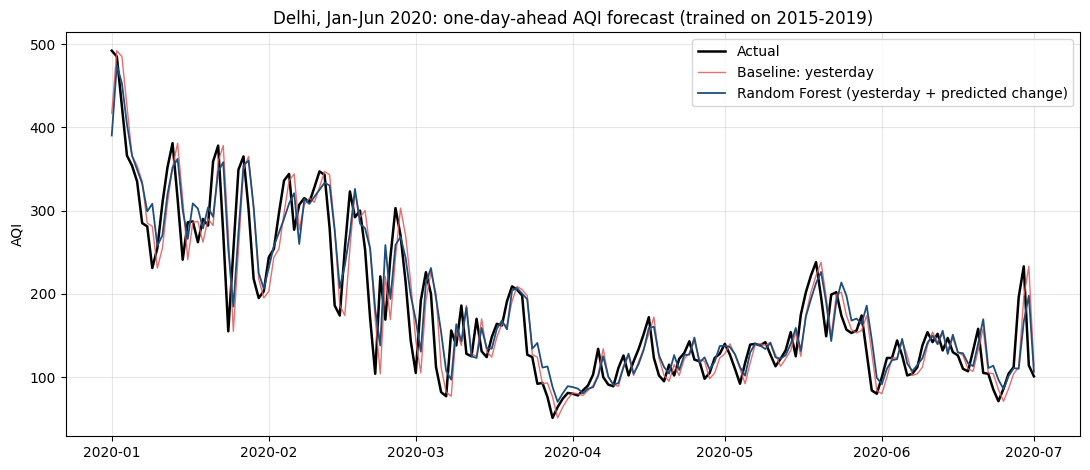

In [8]:
os.makedirs('reports/figures', exist_ok=True)

# 1. comparison table (all cities and Delhi)
dl = test[test['city'] == 'Delhi']
rows = []
for name, col in methods.items():
    rows.append({'method': name,
                 'RMSE_all': round(rmse(test['AQI'], test[col]), 1),
                 'MAE_all': round(mae(test['AQI'], test[col]), 1),
                 'RMSE_Delhi': round(rmse(dl['AQI'], dl[col]), 1),
                 'MAE_Delhi': round(mae(dl['AQI'], dl[col]), 1)})
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
comparison.to_csv('reports/forecast_comparison.csv', index=False)

# 2. is the gain more than noise? block bootstrap over days
test['ae_persist'] = (test['AQI'] - test['pred_persist']).abs()
test['ae_rf'] = (test['AQI'] - test['pred_rf_delta']).abs()
per_day = test.groupby('date')[['ae_persist', 'ae_rf']].mean()
diff = (per_day['ae_persist'] - per_day['ae_rf']).values      # positive = model better
rng = np.random.default_rng(42)
n, b = len(diff), 14
boot = []
for _ in range(2000):
    starts = rng.integers(0, n - b + 1, size=int(np.ceil(n / b)))
    boot.append(np.concatenate([diff[s:s + b] for s in starts])[:n].mean())
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nMean MAE gain per day: {diff.mean():.2f} AQI points, 95% interval [{lo:.2f}, {hi:.2f}]")
print(f"Share of days where the model beat persistence: {(diff > 0).mean() * 100:.0f}%")

# 3. Delhi actual vs predicted
d = dl.sort_values('date')
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(d['date'], d['AQI'], color='black', linewidth=1.8, label='Actual')
ax.plot(d['date'], d['pred_persist'], color='#E15759', linewidth=1, alpha=0.85,
        label='Baseline: yesterday')
ax.plot(d['date'], d['pred_rf_delta'], color='#1F4E79', linewidth=1.3,
        label='Random Forest (yesterday + predicted change)')
ax.set_title('Delhi, Jan-Jun 2020: one-day-ahead AQI forecast (trained on 2015-2019)')
ax.set_ylabel('AQI')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('reports/figures/04_delhi_forecast.png', dpi=150)
plt.show()